**Eye-Tracking & Neurocognitive Intelligence | Reading Comprehension & Neurocognitive Modelling | Presented by: Reza Saadatyar (2026)**

**03 | Classical ML and Text-Based Baselines**

![Classical ML and Text-Based Baselines — scientific workflow](../../images/03_classical_ml_and_text_baselines.svg)

**Objective:** Compare gaze-only, text-only and combined classical predictors, including a training-fitted lexical TF-IDF comparator.

**Dataset:** Trial-level feature table, fixed participant assignments and local paragraph-text table from Notebook 02.

**Scope:** Fit fixed classical candidates and compare gaze, text and combined representations using Validation; save held-out scores.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("reading_comprehension_modelling")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# --------------------------- 3. Study Dependencies ---------------------------
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r",
     str(root / "reading_comprehension_modelling" / "requirements.txt")],
    check=True,
)

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 5. Classical Modelling and Evaluation -------------------
from reading_models import classical_predictions, CLASSICAL
from reading_evaluation import metric

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from onestop_io import validate_splits, validate_trial_index

# ------------------- 8. Output Directory and Setup Summary -------------------
out_dir = root / "reading_comprehension_modelling" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
processed = root / "data" / "processed" / "onestop"
processed.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)
print("Study outputs:", out_dir)
print("Local data directory:", processed)
print("Python:", sys.version.split()[0])


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/reading_comprehension_modelling/output
Local data directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/onestop
Python: 3.13.18


**02. Load Matched Trial Features and Participant Roles**

Read the fixed trial table and split assignments. The local paragraph table contains text for the lexical comparator; it must match the indexed trials. The model allowlists exclude all answer and identity fields.

**Recorded input support:** All 9,718 eligible trial identities and the two fixed participant protocols are retained. The classical run used the local paragraph-text cache and the saved feature table; the lexical comparators use whole-paragraph text rather than fixated-word subsets.

In [3]:
# =========== 02. Load Matched Trial Features and Participant Roles ===========

# ------------------- 1. Load and Reconcile Trial Features --------------------
identity = ["trial_id","participant_id","trial_index","article_batch",
            "article_key","paragraph_key","question_key","difficulty_level"]
table = pd.read_csv(out_dir/"02_trial_features.csv",dtype={c:str for c in identity})
index = pd.read_csv(out_dir/"01_trial_index.csv",dtype=str)
index["is_correct"] = index.is_correct.astype(int)
validate_trial_index(index,table)

# --------------- 2. Load Participant Roles and Paragraph Text ----------------
splits = pd.read_csv(out_dir/"01_participant_splits.csv",dtype=str)
paragraph_text = pd.read_csv(processed/"02_paragraph_text.csv",dtype=str)
validate_splits(table,splits)
print("Classical candidates:",CLASSICAL)


Classical candidates: ['prior', 'logistic_gaze', 'logistic_text', 'logistic_fusion', 'forest_gaze', 'forest_text', 'forest_fusion', 'xgb_gaze', 'xgb_text', 'xgb_fusion', 'tfidf_text', 'tfidf_fusion']


**03. Fit Classical Models and Lexical Baselines**

Compare a Training prevalence reference, Logistic Regression, Random Forest and XGBoost for gaze-only, text-only and combined scalar predictors. Also compare paragraph TF-IDF Logistic Regression with and without gaze features. Imputation, scaling, vocabulary and class weights are Training-only. The decision threshold is fixed at 0.5.

**Recorded prediction coverage:** All 12 candidates were fitted or evaluated as specified for each of the two protocols. The saved table contains 101,064 unique candidate–protocol–trial scores: 1,943 Validation and 1,944 Test trials per candidate in Protocol A, and 1,295 Validation and 3,240 Test trials per candidate in Protocol B. Scores are finite and within [0, 1]. No Training prediction rows are included.

In [4]:
# ============== 03. Fit Classical Models and Lexical Baselines ===============

# --------------------- 1. Fit Fixed Classical Candidates ---------------------
classical, importance = classical_predictions(table,splits,paragraph_text,seed=17)

# --------------------- 2. Summarise Prediction Coverage ----------------------
print("Prediction rows:",len(classical))


Prediction rows: 101064


**04. Examine Validation Evidence**

Only Validation labels are scored here. Test scores are saved without outcome columns; Notebook 05 uses the fixed candidates and Validation selection before calculating Test metrics. Permutation importance for scalar predictors uses Validation only and measures model dependence, not causal effects.

**Recorded Validation evidence:** The highest classical Macro F1 is 0.5582 for `tfidf_fusion` in Protocol A and 0.5698 for `tfidf_text` in Protocol B. The corresponding prevalence references achieve 0.4472 and 0.4487 Macro F1, with zero incorrect-response recall despite accuracy near 81%. The TF-IDF fusion-minus-text differences are +0.0171 (A) and -0.0060 (B); adding gaze to text does not consistently improve Validation performance across estimator families. All three scalar fusion candidates outperform their gaze-only counterparts in both protocols. These comparisons are descriptive, not uncertainty-adjusted effects. Both Validation partitions can share articles with their Training partitions; Protocol B's unseen-article assessment is reserved for its Test partition.

The permutation table contains 168 scalar-feature entries across the two protocols. For example, `fix_count` in A logistic fusion has a mean Macro F1 decrease of 0.0519 and `mean_word_chars` in B logistic fusion has a decrease of 0.0594. These three-repeat permutation summaries describe fitted model dependence and are not causal effects or confidence intervals. Final candidate selection will include the neural models from Notebook 04; no Test metrics are calculated here.

,protocol,model,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
7,A_unseen_people,tfidf_fusion,1943,0.632012,0.558242,0.614018,0.652504,0.294521,0.278920,0.584906,0.223360
8,A_unseen_people,tfidf_text,1943,0.607308,0.541105,0.602869,0.641932,0.293289,0.264988,0.595687,0.228612
2,A_unseen_people,forest_text,1943,0.609882,0.538313,0.593133,0.626358,0.269948,0.260223,0.566038,0.223845
9,A_unseen_people,xgb_fusion,1943,0.605764,0.516463,0.550433,0.592387,0.264384,0.232022,0.460916,0.233615
11,A_unseen_people,xgb_text,1943,0.559959,0.511845,0.592141,0.637947,0.302416,0.248441,0.644205,0.235017
3,A_unseen_people,logistic_fusion,1943,0.578487,0.510961,0.564465,0.595281,0.258763,0.236471,0.541779,0.240239
10,A_unseen_people,xgb_gaze,1943,0.579516,0.491597,0.521856,0.537014,0.213364,0.208115,0.428571,0.240681
5,A_unseen_people,logistic_text,1943,0.545033,0.491393,0.557176,0.580649,0.241002,0.227418,0.576819,0.245929
4,A_unseen_people,logistic_gaze,1943,0.555327,0.487908,0.535737,0.553226,0.226993,0.215686,0.504043,0.243120
0,A_unseen_people,forest_fusion,1943,0.795162,0.479628,0.507886,0.576555,0.237990,0.271186,0.043127,0.167609


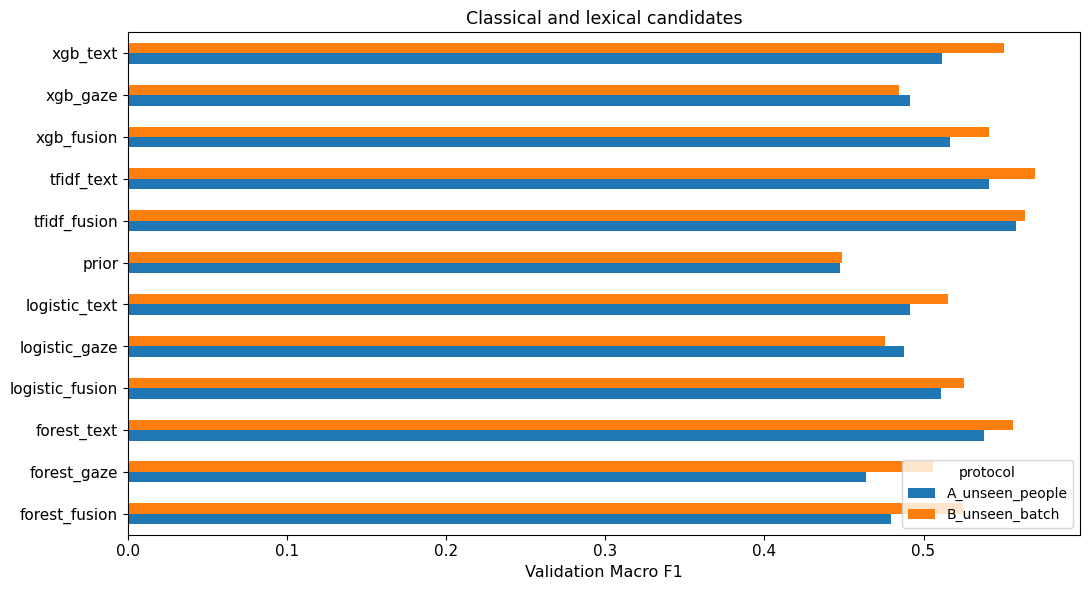

In [5]:
# ====================== 04. Examine Validation Evidence ======================

# -------------------- 1. Summarise Validation Performance --------------------
v = classical[classical.role.eq("validation")].merge(
    table[["trial_id","is_correct"]],on="trial_id",validate="many_to_one")
validation = pd.DataFrame([dict(protocol=p,model=m,**metric(g.is_correct,g.p_correct))
                           for (p,m),g in v.groupby(["protocol","model"])])
display(validation.sort_values(["protocol","macro_f1"],ascending=[True,False]))

# ----------------------- 2. Plot Validation Comparison -----------------------
fig, ax = plt.subplots(figsize=(11,6))
validation.pivot(index="model",columns="protocol",values="macro_f1").plot.barh(ax=ax)
ax.set(xlabel="Validation Macro F1",ylabel="",title="Classical and lexical candidates")
fig.tight_layout()
save_figure(fig,out_dir/"03_validation_comparison.png")
plt.show()


**05. Save Classical Prediction Scores**

Export one score per candidate and eligible Validation or Test trial. The scalar-model permutation summaries are also saved. No Test-informed fitting or selection occurs in this notebook.

**Handoff:** All four stage outputs are recorded in `output/`. Notebook 04 independently reads the fixed cohort, feature table, splits and the local `data/processed/onestop/02_fixation_sequences.npz` cache. Preserve the current classical scores for Notebook 05; neither classical fitting nor final Test scoring needs to be repeated to start Notebook 04.

In [6]:
# =================== 05. Save Classical Prediction Scores ====================

# ---------------- 1. Save Predictions and Validation Evidence ----------------
classical.to_csv(out_dir/"03_classical_predictions.csv",index=False)
validation.to_csv(out_dir/"03_validation_metrics.csv",index=False)
importance.to_csv(out_dir/"03_validation_feature_importance.csv",index=False)

# ------------------------ 2. Package Current Outputs -------------------------
download_outputs_from_colab(out_dir,"03")


------------------------------------------------------------------------
Notebook 03
Files packaged: 4
  + 03_classical_predictions.csv
  + 03_validation_comparison.png
  + 03_validation_feature_importance.csv
  + 03_validation_metrics.csv
Download ZIP from Colab Contents: /content/reading_comprehension_modelling_Notebook_03_Outputs.zip
